# Tuần 7 — Ablation và phân tích chiến thuật của Ly

Notebook chỉ gọi runner canonical và đọc config/raw log; không sao chép thuật toán.

Từ thư mục `Caro_AI_Project`, chạy `python benchmarks/run_ablation_w78.py run` trước rồi Run All. Lệnh mặc định ghi rõ `official=False` khi working tree chưa sạch. Chỉ dùng `run --official` sau khi đạt cổng baseline trong kế hoạch (working tree sạch, full regression đạt và config đã khóa). Raw log nằm tại `results/w78_ablation_ly/`, không commit vào Git.

`analyze` tái tạo bảng, biểu đồ và bốn board snapshot từ raw log đã kiểm tra checksum. Không điều chỉnh agent hoặc cấu hình theo kết quả đã xem.

In [6]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'core').is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from benchmarks.run_ablation_w78 import load_config, load_raw, analyze, DEFAULT_CONFIG
import pandas as pd
from IPython.display import display, Markdown, SVG
CONFIG = load_config(DEFAULT_CONFIG)
OUTPUT = ROOT / 'results/w78_ablation_ly'
ASSETS = ROOT / 'docs/report/assets'
manifest, raw = load_raw(OUTPUT)
assert CONFIG == manifest['config'], 'Config differs from the measured run'
assert CONFIG['frozen_sources'] == manifest['identity']['frozen_sources']
summary, cases = analyze(OUTPUT, ASSETS)
assert len(cases) == 4, 'Need two distinct wins and two distinct failures'
print({'run_id': CONFIG['run_id'], 'commit': manifest['identity']['git_commit'], 'official': manifest['identity']['official'], 'hardware': manifest['hardware']})

{'run_id': 'ly-w78-ablation-v1', 'commit': '45870d83ff7f7fe352476bb83521603e3f56419c', 'official': False, 'hardware': {'platform': 'Windows-11-10.0.26100-SP0', 'processor': 'AMD64 Family 23 Model 96 Stepping 1, AuthenticAMD', 'logical_cpus': 6, 'python': '3.13.5'}}


## A1 — Alpha-Beta ON/OFF

Same fixed depth, scenario, move ordering and seed. Warm-up is excluded. Action/score equality is checked for every pair; nodes count step calls across iterative deepening.

,scenario,alpha_beta,runs,action,score,nodes_mean,mean_ms,p95_ms,node_reduction_fraction
0,block_x_gap,False,30,"(4, 5)",-220.160784,2076.0,262.866903,599.3775,0.895954
1,block_x_gap,True,30,"(4, 5)",-220.160784,216.0,51.556327,105.2388,0.895954
2,midgame_x,False,30,"(2, 8)",-0.035294,1336.0,154.063957,429.3180,0.890719
3,midgame_x,True,30,"(2, 8)",-0.035294,146.0,37.578167,74.4297,0.890719
4,near_full_x,False,30,"(10, 7)",-10.025490,12.0,8.318927,19.4028,0.083333
5,near_full_x,True,30,"(10, 7)",-10.025490,11.0,7.838150,27.7387,0.083333
6,opening_x,False,30,"(5, 5)",0.001961,10.0,0.987967,2.1032,0.000000
7,opening_x,True,30,"(5, 5)",0.001961,10.0,1.019510,3.4726,0.000000


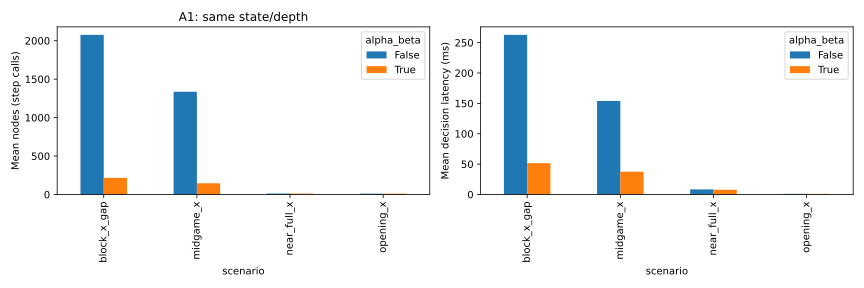

In [7]:
display(pd.DataFrame(summary['a1']))
display(SVG(filename=str(ASSETS / 'ablation_a1.svg')))

Thirty timing repetitions on a deterministic state measure latency variation, not independent tactical quality. The table records actual node reduction; it does not assume pruning always improves wall-clock time.

## A2 — 100 / 400 / 1000 simulations

Thirty matched seeds and both sides give 60 full games per profile against Heuristic. All constructor options remain fixed; only the simulation budget varies. The declared random-rollout horizon-4 profile differs from the tournament profile. Tactical overrides consume zero simulations and are reported separately.

,simulations,paired_seeds,games,wins,draws,losses,score_rate,score_as_x,score_as_o,mean_ms,p95_ms,agent_moves,actual_simulations,nodes,tactical_override_moves,unique_trajectories,seed_score_std
0,100,30,60,0,0,60,0.000000,0.000000,0.000000,51.807427,125.8779,364,34600,34964,18,60,0.000000
1,400,30,60,4,1,55,0.075000,0.066667,0.083333,214.549413,487.0571,539,195200,194945,51,60,0.172603
2,1000,30,60,5,1,54,0.091667,0.150000,0.033333,563.890737,1131.8954,696,630000,627035,66,60,0.228066


,comparison,paired_seeds,mean_score_delta,seed_delta_std
0,400-100,30,0.075000,0.172603
1,1000-100,30,0.091667,0.228066


,simulations,seed_index,seed,paired_score,score_as_x,score_as_o
0,100,0,293621622,0.0,0.0,0.0
1,100,1,293621623,0.0,0.0,0.0
2,100,2,293621624,0.0,0.0,0.0
3,100,3,293621625,0.0,0.0,0.0
4,100,4,293621626,0.0,0.0,0.0
...,...,...,...,...,...,...
85,1000,25,293621647,0.0,0.0,0.0
86,1000,26,293621648,0.5,1.0,0.0
87,1000,27,293621649,0.0,0.0,0.0
88,1000,28,293621650,0.0,0.0,0.0


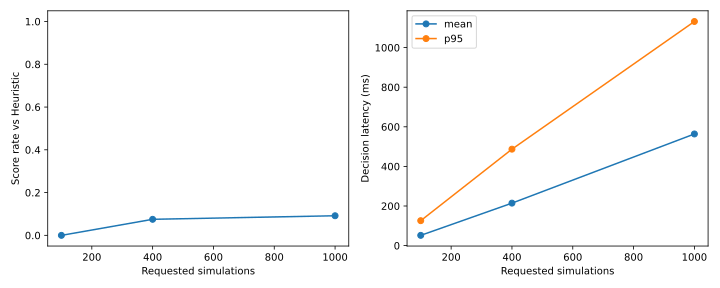

In [8]:
display(pd.DataFrame(summary['a2']))
display(pd.DataFrame(summary['paired']))
display(pd.DataFrame(summary['sensitivity']))
display(SVG(filename=str(ASSETS / 'ablation_a2.svg')))

Score is (wins + 0.5 draws) / games from MCTS perspective. Pair deltas compare the same seeds across budgets. X/O scores and distinct trajectory counts expose side effects and duplicated observations; these runs do not establish universal playing strength.

## Two wins and two failure cases

Each snapshot is replayed from a checksummed raw game and displayed just before the selected MCTS move. No synthetic failure is created if the run does not supply enough distinct trajectories.

,kind,game_id,candidate_side,ply,action,note
0,win,A2-n1000-s5-side1,1,21,"(8, 1)",MCTS chọn nước thắng ngay hợp lệ.
1,win,A2-n1000-s5-side-1,-1,18,"(7, 2)",MCTS chọn nước thắng ngay hợp lệ.
2,failure,A2-n1000-s0-side1,1,33,"(3, 4)",Có nhiều hơn một nước thắng ngay của đối thủ: ...
3,failure,A2-n1000-s0-side-1,-1,36,"(4, 4)",Có nhiều hơn một nước thắng ngay của đối thủ: ...


### win: A2-n1000-s5-side1

MCTS chọn nước thắng ngay hợp lệ.

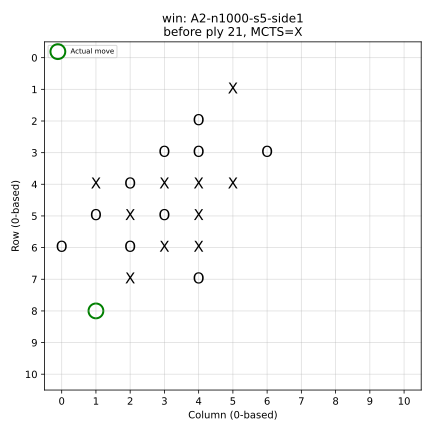

### win: A2-n1000-s5-side-1

MCTS chọn nước thắng ngay hợp lệ.

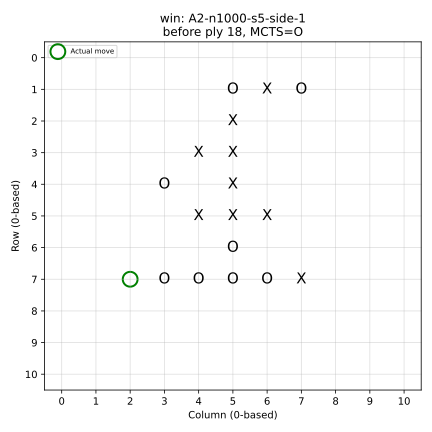

### failure: A2-n1000-s0-side1

Có nhiều hơn một nước thắng ngay của đối thủ: một nước chặn không thể giải hết threat.

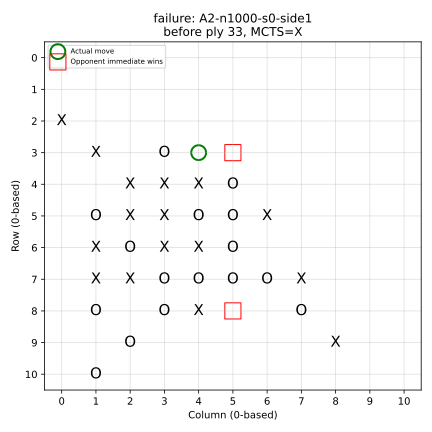

### failure: A2-n1000-s0-side-1

Có nhiều hơn một nước thắng ngay của đối thủ: một nước chặn không thể giải hết threat.

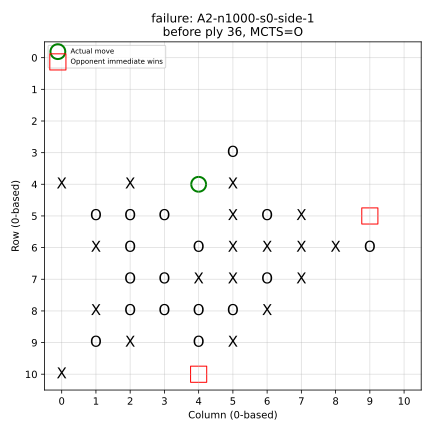

In [9]:
display(pd.DataFrame([{k: c[k] for k in ('kind','game_id','candidate_side','ply','action','note')} for c in cases]))
for case in cases:
    display(Markdown(f"### {case['kind']}: {case['game_id']}\n\n{case['note']}"))
    display(SVG(filename=str(ASSETS / case['snapshot'])))

## Interpretation, provenance and limits

The generated report below contains measured values and case notes. Do not adjust frozen agents after reading the results. A final review against results-v1 and the assembled report requires those artifacts from their owners.

In [10]:
display(Markdown((ASSETS / 'Ket_qua_Ablation_W78.md').read_text(encoding='utf-8')))

# Hai ablation tuần 7–8 — Ly

Run: `ly-w78-ablation-v1`; commit `45870d83ff7f7fe352476bb83521603e3f56419c`; official=False.

## A1 — Alpha-Beta ON/OFF

|scenario|alpha_beta|runs|action|score|nodes_mean|mean_ms|p95_ms|node_reduction_fraction|
|---|---|---|---|---|---|---|---|---|
|block_x_gap|False|30|(4, 5)|-220.1608|2076.0000|262.8669|599.3775|0.8960|
|block_x_gap|True|30|(4, 5)|-220.1608|216.0000|51.5563|105.2388|0.8960|
|midgame_x|False|30|(2, 8)|-0.0353|1336.0000|154.0640|429.3180|0.8907|
|midgame_x|True|30|(2, 8)|-0.0353|146.0000|37.5782|74.4297|0.8907|
|near_full_x|False|30|(10, 7)|-10.0255|12.0000|8.3189|19.4028|0.0833|
|near_full_x|True|30|(10, 7)|-10.0255|11.0000|7.8382|27.7387|0.0833|
|opening_x|False|30|(5, 5)|0.0020|10.0000|0.9880|2.1032|0.0000|
|opening_x|True|30|(5, 5)|0.0020|10.0000|1.0195|3.4726|0.0000|

Action và score trùng trong mọi cặp. Node là số lần step, cộng dồn iterative deepening; không phải số state duy nhất. Đây là 30 phép lặp thời gian trên từng state cố định, không phải 30 vị trí chiến thuật độc lập.

## A2 — Chỉ thay simulations

|simulations|paired_seeds|games|wins|draws|losses|score_rate|score_as_x|score_as_o|mean_ms|p95_ms|agent_moves|actual_simulations|nodes|tactical_override_moves|unique_trajectories|seed_score_std|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|100|30|60|0|0|60|0.0000|0.0000|0.0000|51.8074|125.8779|364|34600|34964|18|60|0.0000|
|400|30|60|4|1|55|0.0750|0.0667|0.0833|214.5494|487.0571|539|195200|194945|51|60|0.1726|
|1000|30|60|5|1|54|0.0917|0.1500|0.0333|563.8907|1131.8954|696|630000|627035|66|60|0.2281|

|comparison|paired_seeds|mean_score_delta|seed_delta_std|
|---|---|---|---|
|400-100|30|0.0750|0.1726|
|1000-100|30|0.0917|0.2281|

Mỗi mức có 30 cặp seed × 2 vai = 60 ván từ bàn rỗng, cùng đối thủ Heuristic. Rollout random có horizon 4, leaf evaluation pattern; các tham số khác giữ nguyên. Đây là cấu hình ablation công bố riêng, không đồng nhất với MCTS 8 simulations/epsilon_heuristic của tournament.
Tactical pre-check có thể trả ngay với 0 simulations; bảng ghi cả tổng simulations thực tế và số nước override. Latency dùng thời gian bao quanh choose_action, không gồm render.
Seed sensitivity nằm trong ablation_sensitivity.csv; paired delta dùng cùng seed giữa các ngân sách. Các trajectory trùng không được coi là quan sát độc lập. Chênh lệch X/O là mô tả theo vai, không chứng minh quan hệ nhân quả hoặc sức mạnh tổng quát.

## Hai ván thắng và hai failure case

### win — A2-n1000-s5-side1

![Snapshot](case_1_win.svg)

MCTS là X (đi trước), ply 21, action (8, 1). MCTS chọn nước thắng ngay hợp lệ.

### win — A2-n1000-s5-side-1

![Snapshot](case_2_win.svg)

MCTS là O (đi sau), ply 18, action (7, 2). MCTS chọn nước thắng ngay hợp lệ.

### failure — A2-n1000-s0-side1

![Snapshot](case_3_failure.svg)

MCTS là X (đi trước), ply 33, action (3, 4). Có nhiều hơn một nước thắng ngay của đối thủ: một nước chặn không thể giải hết threat.

### failure — A2-n1000-s0-side-1

![Snapshot](case_4_failure.svg)

MCTS là O (đi sau), ply 36, action (4, 4). Có nhiều hơn một nước thắng ngay của đối thủ: một nước chặn không thể giải hết threat.

## Tái tạo và giới hạn

Tất cả bảng, hình và snapshot sinh từ raw shard đã đối chiếu checksum và replay. Không có số liệu nhập tay. Chạy `python benchmarks/run_ablation_w78.py analyze` để tái tạo.
Không tune agent/model từ kết quả này. Poster và chương thuật toán do Ly tự thực hiện. Bản báo cáo cuối/results-v1 của nhóm chưa có để review đối chiếu đầy đủ.

Hardware: `{"platform": "Windows-11-10.0.26100-SP0", "processor": "AMD64 Family 23 Model 96 Stepping 1, AuthenticAMD", "logical_cpus": 6, "python": "3.13.5"}`.
